# Lab 7: Fast Fourier Transform (FFT)

## **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:

### 1. Do the FFT using scipy and Numpy rutines (see notebook)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import urllib.request
import pandas as pd
from scipy import interpolate
from scipy import integrate
from playsound3 import playsound
from scipy.fft import fft,fftfreq,ifft,fftshift,ifftshift


In [3]:
url="https://raw.githubusercontent.com/alexphy08/CursoFisicaComputacional/b41e392fd6bd86ad84a54b2d4a078ee8d0901d7b/Sesiones/Fourier/Nota_CM_piano.mp3"
playsound(url)

In [2]:
url = "https://raw.githubusercontent.com/alexphy08/CursoFisicaComputacional/b41e392fd6bd86ad84a54b2d4a078ee8d0901d7b/Sesiones/Fourier/Nota_CM_piano.mp3"
temp_file = "Nota_CM_piano.mp3"

urllib.request.urlretrieve(url, temp_file)
signal,sr=librosa.load(temp_file, sr=None)

print(f"Sample Rate: {sr}")
print(f"Signal Shape: {signal.shape}")

Sample Rate: 44100
Signal Shape: (152064,)


Con numpy y scipy

Number of samples: 152064


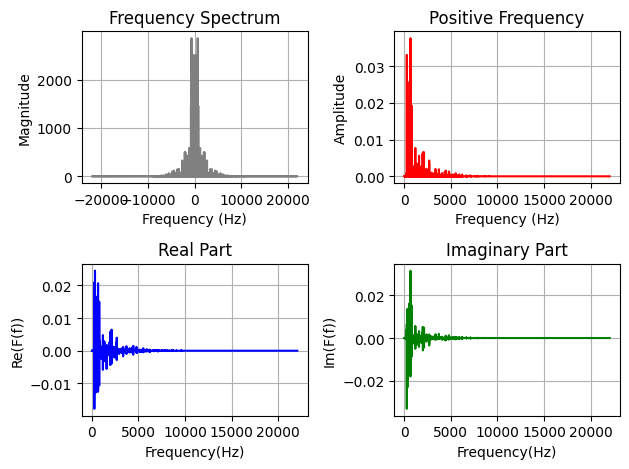

In [3]:
N=len(signal)
print(f"Number of samples: {N}")
yf=fft(signal)
xf=fftfreq(N,1/sr)

plt.subplot(2,2,1)
plt.plot(xf,np.abs(yf),color='gray')
plt.title('Frequency Spectrum')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.grid()

plt.subplot(2,2,2)
plt.plot(xf[:N//2],2.0/N*np.abs(yf[:N//2]),color='red') 
plt.title('Positive Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.grid()

plt.subplot(2,2,3)
plt.plot(xf[:N//2],2.0/N*np.real(yf[:N//2]),color='blue')
plt.title('Real Part')
plt.xlabel('Frequency(Hz)')
plt.ylabel('Re(F(f))')
plt.grid()

plt.subplot(2,2,4)
plt.plot(xf[:N//2],2.0/N*np.imag(yf[:N//2]),color='green')
plt.title('Imaginary Part')
plt.xlabel('Frequency(Hz)')
plt.ylabel('Im(F(f))')
plt.grid()

plt.tight_layout()
plt.show()

### 2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?

C:\Users\crist\AppData\Local\Temp\ipykernel_15668\1232694575.py:15: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  int_Re=integrate.quad(f_interp,x.min(),x.max(),weight='cos',wvar=wvar)[0]
C:\Users\crist\AppData\Local\Temp\ipykernel_15668\1232694575.py:16: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from sp

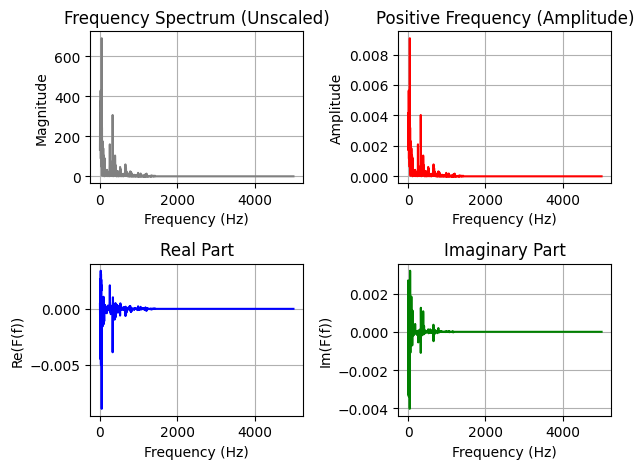

In [4]:
def FT(signal,sr,f_max,n):
    x=np.arange(len(signal))/sr
    y=signal

    f_interp=interpolate.interp1d(x,y,kind='cubic',fill_value='extrapolate')

    T=len(signal)/sr
    f_min=1/T 
    w=np.linspace(f_min,f_max,n) 

    df=[]
    for i in range(len(w)):
        wvar=2*np.pi*w[i]
        
        int_Re=integrate.quad(f_interp,x.min(),x.max(),weight='cos',wvar=wvar)[0]
        int_Im=-integrate.quad(f_interp,x.min(),x.max(),weight='sin',wvar=wvar)[0]
        
        ARew=int_Re*(2/T)
        AImw=int_Im*(2/T)
        
        AMP=np.sqrt(ARew**2+AImw**2)
        ANG=np.arctan2(AImw,ARew)
        
        df.append([w[i],ARew,AImw,AMP,ANG])

    return pd.DataFrame(df,columns=['w','ReTw','ImTw','AMP','ANG'])

df=FT(signal,sr,5000,2000)
N=len(signal)

plt.subplot(2,2,1)
plt.plot(df['w'],df['AMP']*(N/2), color='gray') 
plt.title('Frequency Spectrum (Unscaled)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.grid()

plt.subplot(2,2,2)
plt.plot(df['w'],df['AMP'], color='red') 
plt.title('Positive Frequency (Amplitude)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.grid()

plt.subplot(2,2,3)
plt.plot(df['w'],df['ReTw'], color='blue')
plt.title('Real Part')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Re(F(f))')
plt.grid()

plt.subplot(2,2,4)
plt.plot(df['w'],df['ImTw'], color='green')
plt.title('Imaginary Part')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Im(F(f))')
plt.grid()

plt.tight_layout()
plt.show()

## **Exercise 1** : Do the FFT for an Imagen

Choose an Imagen

### 1. Do the FFT using scipy (see notebook)

Con scipy

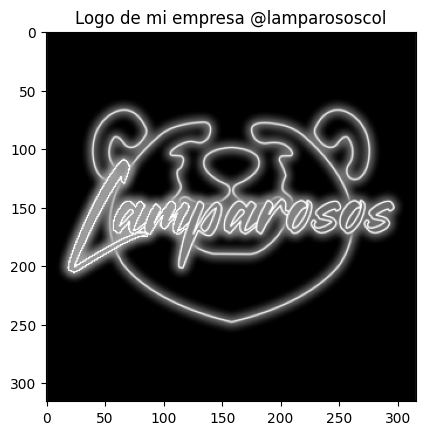

In [42]:
imagen=plt.imread("logo2.1.jpg")

foto_gris=np.mean(imagen[::6,::6],-1)
plt.imshow(foto_gris,cmap='gray')
plt.title('Logo de mi empresa @lamparososcol')
plt.show()

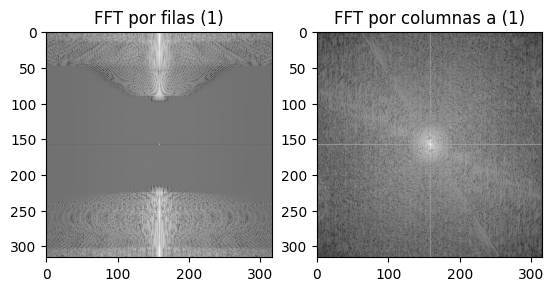

In [43]:
vert=np.zeros_like(foto_gris,dtype='complex')
hori=np.zeros_like(vert,dtype='complex')

for i in range(foto_gris.shape[0]):
    vert[i,:]=fft(foto_gris[i,:])

vertical=fftshift(vert)

for i in range(vert.shape[1]):
    hori[:,i]=fft(vert[:,i])

horizontal=fftshift(hori)

plt.subplot(1,2,1)
plt.imshow(np.log(abs(vertical)),cmap='gray')
plt.title('FFT por filas (1)')
plt.subplot(1,2,2)
plt.imshow(np.log(abs(horizontal)),cmap='gray')
plt.title('FFT por columnas a (1)')
plt.show()

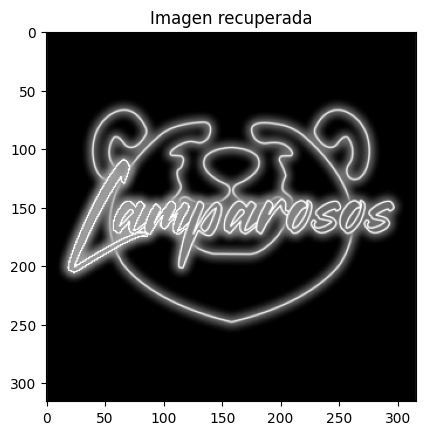

In [44]:
hori_inversa=np.zeros_like(horizontal,dtype='complex')

for i in range(horizontal.shape[1]):
    hori_inversa[:,i]=ifft(horizontal[:,i])

foto_recuperada=ifft(hori_inversa)
plt.imshow(abs(foto_recuperada),cmap='gray')
plt.title('Imagen recuperada')
plt.show()

### 2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?

### 3. Do the inverse FFT and reconstruc the original imagene. <br> Do you get a similar result? Compare the original and the reconstructed signal.

In [45]:
M, N = foto_gris.shape

def DFT_1D(x,signo=-1):
    N=len(x)
    n=np.arange(N)
    X=np.zeros(N,dtype=complex)
    for k in range(N):
        X[k]=np.sum(x*np.exp(signo*2j*np.pi*k*n/N))
    return X

def DFT_2D(f,signo=-1):
    M,N=f.shape
    temp=np.zeros((M,N),dtype=complex)
    F=np.zeros((M,N),dtype=complex)

    for i in range(M):
        temp[i,:]=DFT_1D(f[i,:],signo)

    for j in range(N):
        F[:,j]=DFT_1D(temp[:,j],signo)

    return F

Error máximo: 2.795275122480234e-11


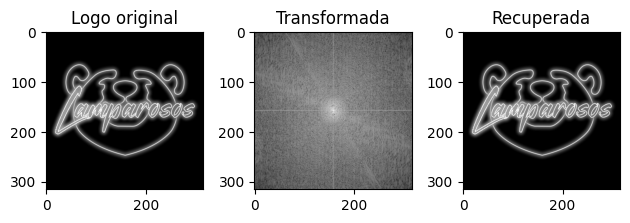

In [47]:
F=DFT_2D(foto_gris)

recuperada=np.real(DFT_2D(F,1))/(M*N)

print(f"Error máximo: {np.max(np.abs(foto_gris-recuperada))}")

F_centrada = np.roll(F, (M//2, N//2), axis=(0, 1))
espectro = np.log1p(np.abs(F_centrada))

plt.subplot(1,3,1)
plt.imshow(foto_gris,cmap="gray")
plt.title("Logo original")

plt.subplot(1,3,2)
plt.imshow(espectro,cmap="gray")
plt.title("Transformada")

plt.subplot(1,3,3)
plt.imshow(recuperada,cmap="gray")
plt.title("Recuperada")

plt.tight_layout()
plt.show()